In [1]:
# ============================================================
# RAINFALL PREDICTION USING MACHINE LEARNING
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset splitting
from sklearn.model_selection import train_test_split

# Data preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Machine Learning algorithm
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    precision_recall_curve
)

# Feature importance
from sklearn.inspection import permutation_importance

# Save the trained model
import joblib

print("All required libraries imported successfully!")
print("Ready to begin the Rainfall Prediction project.")

All required libraries imported successfully!
Ready to begin the Rainfall Prediction project.


In [2]:
# ============================================================
# STEP 2: LOAD THE DATASET
# ============================================================

from google.colab import files
import io

# Upload the dataset
uploaded = files.upload()

# Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Dataset loaded successfully!")
print("\nDataset dimensions:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Saving weatherAUS.csv to weatherAUS.csv
Dataset loaded successfully!

Dataset dimensions: (145460, 23)

First 5 rows:


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [3]:
# ============================================================
# STEP 3: EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# 1. Display dataset dimensions
print("1. DATASET DIMENSIONS")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# 2. Display all column names
print("\n2. COLUMN NAMES")
print(df.columns.tolist())

# 3. Display data types and non-null counts
print("\n3. DATASET INFORMATION")
df.info()

# 4. Calculate missing values
print("\n4. MISSING VALUES")
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_values = missing_values.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(missing_values)

# 5. Check duplicate rows
print("\n5. DUPLICATE ROWS")
print("Number of duplicate rows:", df.duplicated().sum())

# 6. Display statistical summary
print("\n6. STATISTICAL SUMMARY")
display(df.describe().round(2))

# 7. Display categorical column summaries
print("\n7. CATEGORICAL COLUMN SUMMARY")
display(df.describe(include="object").T)

1. DATASET DIMENSIONS
Number of rows: 145460
Number of columns: 23

2. COLUMN NAMES
['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']

3. DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  13

,Missing Count,Missing Percentage (%)
Sunshine,69835,48.01
Evaporation,62790,43.17
Cloud3pm,59358,40.81
Cloud9am,55888,38.42
Pressure9am,15065,10.36
Pressure3pm,15028,10.33
WindDir9am,10566,7.26
WindGustDir,10326,7.10
WindGustSpeed,10263,7.06
Humidity3pm,4507,3.10



5. DUPLICATE ROWS
Number of duplicate rows: 0

6. STATISTICAL SUMMARY


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,143975.00,144199.00,142199.00,82670.00,75625.00,135197.00,143693.00,142398.00,142806.00,140953.00,130395.00,130432.00,89572.00,86102.00,143693.00,141851.00
mean,12.19,23.22,2.36,5.47,7.61,40.04,14.04,18.66,68.88,51.54,1017.65,1015.26,4.45,4.51,16.99,21.68
std,6.40,7.12,8.48,4.19,3.79,13.61,8.92,8.81,19.03,20.80,7.11,7.04,2.89,2.72,6.49,6.94
min,-8.50,-4.80,0.00,0.00,0.00,6.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-7.20,-5.40
25%,7.60,17.90,0.00,2.60,4.80,31.00,7.00,13.00,57.00,37.00,1012.90,1010.40,1.00,2.00,12.30,16.60
50%,12.00,22.60,0.00,4.80,8.40,39.00,13.00,19.00,70.00,52.00,1017.60,1015.20,5.00,5.00,16.70,21.10
75%,16.90,28.20,0.80,7.40,10.60,48.00,19.00,24.00,83.00,66.00,1022.40,1020.00,7.00,7.00,21.60,26.40
max,33.90,48.10,371.00,145.00,14.50,135.00,130.00,87.00,100.00,100.00,1041.00,1039.60,9.00,9.00,40.20,46.70



7. CATEGORICAL COLUMN SUMMARY


,count,unique,top,freq
Date,145460,3436,2017-06-24,49
Location,145460,49,Canberra,3436
WindGustDir,135134,16,W,9915
WindDir9am,134894,16,N,11758
WindDir3pm,141232,16,SE,10838
RainToday,142199,2,No,110319
RainTomorrow,142193,2,No,110316


TARGET VARIABLE: RainTomorrow

Value counts:
RainTomorrow
No     110316
Yes     31877
NaN      3267
Name: count, dtype: int64

Percentage distribution:
RainTomorrow
No     75.84%
Yes    21.91%
NaN     2.25%
Name: proportion, dtype: object


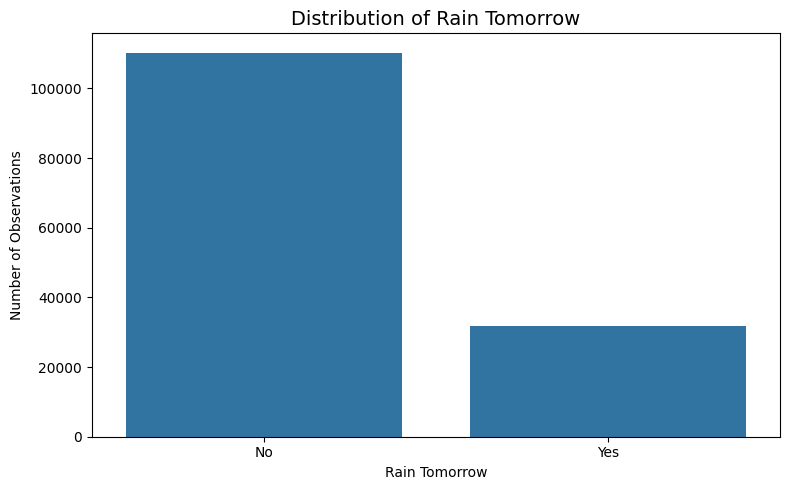

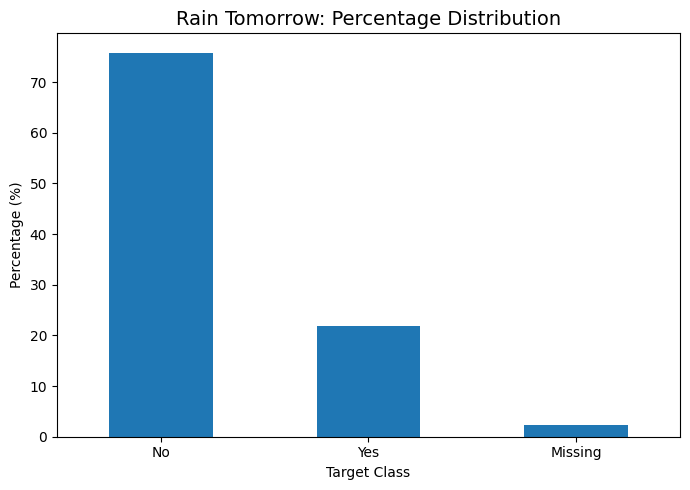

In [4]:
# ============================================================
# STEP 4: TARGET VARIABLE ANALYSIS
# ============================================================

# 1. Check the target variable
print("TARGET VARIABLE: RainTomorrow")
print("\nValue counts:")
print(df["RainTomorrow"].value_counts(dropna=False))

# 2. Calculate percentages, including missing labels
print("\nPercentage distribution:")
print(
    (df["RainTomorrow"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .astype(str) + "%"
)

# 3. Visualize the target distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="RainTomorrow",
    order=["No", "Yes"]
)

plt.title("Distribution of Rain Tomorrow", fontsize=14)
plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

# 4. Plot the percentage distribution
target_percentages = (
    df["RainTomorrow"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

target_percentages.index = target_percentages.index.map(
    lambda x: "Missing" if pd.isna(x) else x
)

plt.figure(figsize=(7, 5))
target_percentages.plot(kind="bar")

plt.title("Rain Tomorrow: Percentage Distribution", fontsize=14)
plt.xlabel("Target Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

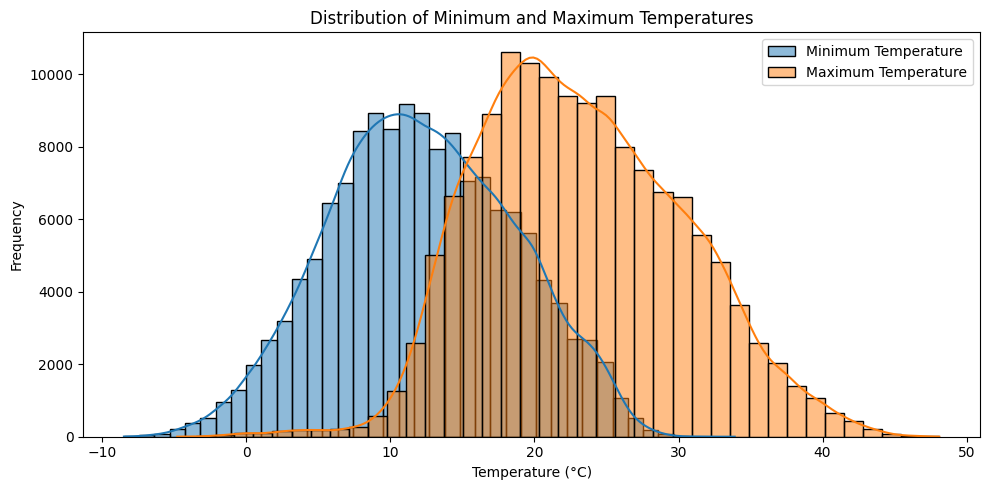

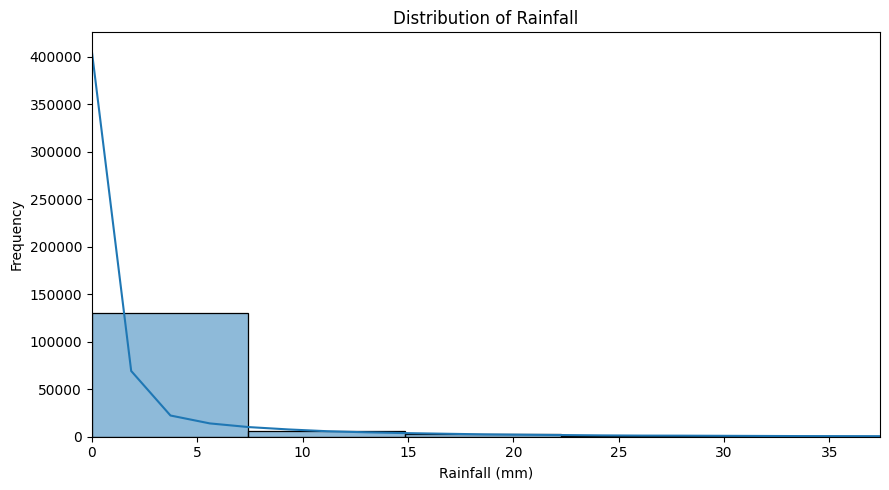

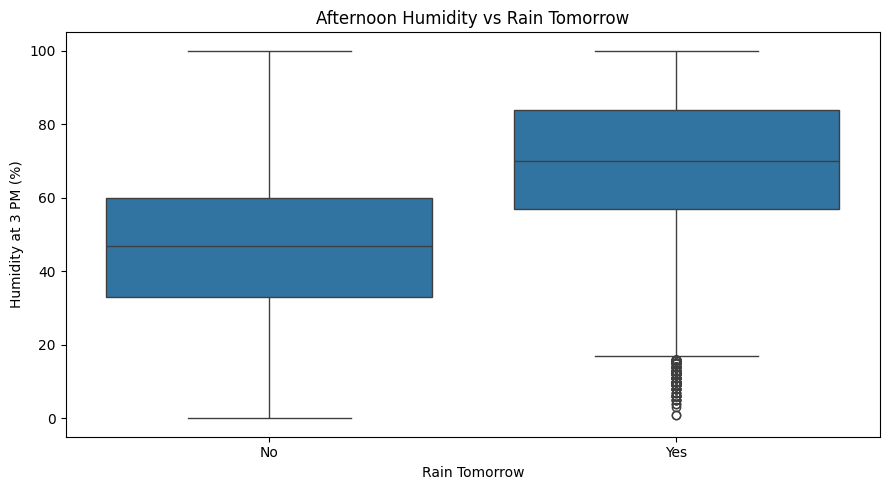

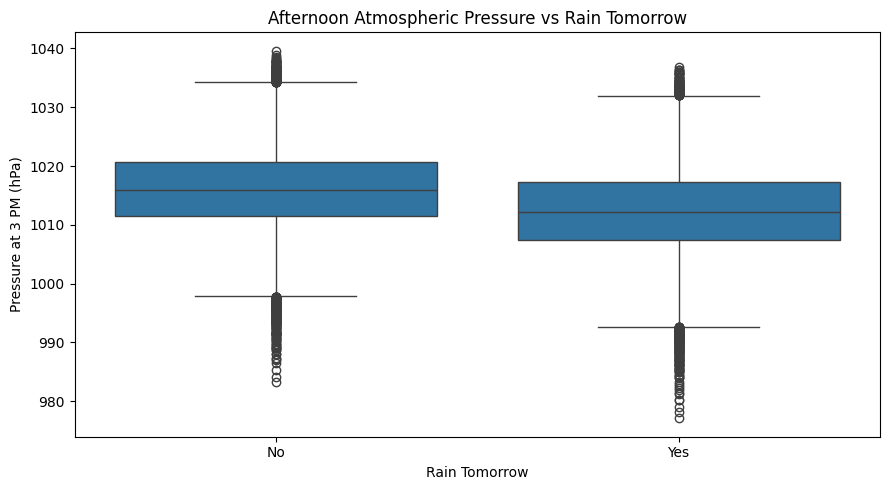

Weather feature visualizations completed successfully!


In [5]:
# ============================================================
# STEP 5: WEATHER FEATURE VISUALIZATION
# ============================================================

# 1. Distribution of minimum and maximum temperatures
plt.figure(figsize=(10, 5))

sns.histplot(df["MinTemp"], bins=40, kde=True, label="Minimum Temperature")
sns.histplot(df["MaxTemp"], bins=40, kde=True, label="Maximum Temperature")

plt.title("Distribution of Minimum and Maximum Temperatures")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


# 2. Rainfall distribution
plt.figure(figsize=(9, 5))

sns.histplot(df["Rainfall"].dropna(), bins=50, kde=True)

plt.title("Distribution of Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Frequency")
plt.xlim(0, df["Rainfall"].quantile(0.99))
plt.tight_layout()
plt.show()


# 3. Humidity comparison
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="RainTomorrow",
    y="Humidity3pm",
    order=["No", "Yes"]
)

plt.title("Afternoon Humidity vs Rain Tomorrow")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Humidity at 3 PM (%)")
plt.tight_layout()
plt.show()


# 4. Pressure comparison
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="RainTomorrow",
    y="Pressure3pm",
    order=["No", "Yes"]
)

plt.title("Afternoon Atmospheric Pressure vs Rain Tomorrow")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Pressure at 3 PM (hPa)")
plt.tight_layout()
plt.show()

print("Weather feature visualizations completed successfully!")

In [6]:
# ============================================================
# STEP 6: DATA CLEANING AND TARGET PREPARATION
# ============================================================

# 1. Display original dataset size
print("Original dataset shape:", df.shape)

# 2. Remove rows with missing target labels
df_clean = df.dropna(subset=["RainTomorrow"]).copy()

print("After removing missing target labels:", df_clean.shape)

# 3. Remove duplicate rows
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

print("Duplicate rows removed:", duplicates_before)
print("Dataset shape after duplicate removal:", df_clean.shape)

# 4. Encode target variable
df_clean["RainTomorrow"] = df_clean["RainTomorrow"].map({
    "No": 0,
    "Yes": 1
})

# 5. Check target distribution after cleaning
print("\nTarget distribution:")
print(df_clean["RainTomorrow"].value_counts())

print("\nTarget distribution percentage:")
print(
    (df_clean["RainTomorrow"].value_counts(normalize=True) * 100)
    .round(2)
)

# 6. Separate features and target
X = df_clean.drop(
    columns=["RainTomorrow", "Date", "RISK_MM"]
)

y = df_clean["RainTomorrow"]

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# 7. Display remaining missing values
print("\nTotal missing feature values:", X.isnull().sum().sum())

print("\nStep 6 completed successfully!")

Original dataset shape: (145460, 23)
After removing missing target labels: (142193, 23)
Duplicate rows removed: 0
Dataset shape after duplicate removal: (142193, 23)

Target distribution:
RainTomorrow
0    110316
1     31877
Name: count, dtype: int64

Target distribution percentage:
RainTomorrow
0    77.58
1    22.42
Name: proportion, dtype: float64


KeyError: "['RISK_MM'] not found in axis"

In [7]:
# ============================================================
# STEP 6 (FIX): SEPARATE FEATURES AND TARGET
# ============================================================

# Columns to exclude from model training
columns_to_drop = ["RainTomorrow", "Date", "RISK_MM"]

# Keep only columns that actually exist in the dataset
columns_to_drop = [
    column for column in columns_to_drop
    if column in df_clean.columns
]

print("Columns excluded:", columns_to_drop)

# Separate input features and target
X = df_clean.drop(columns=columns_to_drop)
y = df_clean["RainTomorrow"]

# Display results
print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values in input features:", X.isnull().sum().sum())

print("\nStep 6 completed successfully!")

Columns excluded: ['RainTomorrow', 'Date']

Feature matrix shape: (142193, 21)
Target vector shape: (142193,)

Feature columns:
['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday']

Missing values in input features: 316559

Step 6 completed successfully!


In [8]:
# ============================================================
# STEP 7: TRAIN-TEST SPLIT
# ============================================================

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("TRAIN-TEST SPLIT COMPLETED")
print("-" * 40)

print("Original dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check class distribution in training and testing sets
print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

print("\nStep 7 completed successfully!")

TRAIN-TEST SPLIT COMPLETED
----------------------------------------
Original dataset: (142193, 21)
Training features: (113754, 21)
Testing features: (28439, 21)

Training target: (113754,)
Testing target: (28439,)

Training target distribution (%):
RainTomorrow
0    77.58
1    22.42
Name: proportion, dtype: float64

Testing target distribution (%):
RainTomorrow
0    77.58
1    22.42
Name: proportion, dtype: float64

Step 7 completed successfully!


In [9]:
# ============================================================
# STEP 8: DATA PREPROCESSING PIPELINE
# ============================================================

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)


# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Number of numerical features: 16
Number of categorical features: 5

Numerical features:
['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']

Categorical features:
['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']

Preprocessing pipeline created successfully!


In [10]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the complete machine learning pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

# Train the model
print("Training Rainfall Prediction Model...")
start_time = time.time()

model.fit(X_train, y_train)

end_time = time.time()

print("\nModel training completed successfully!")
print(f"Training time: {(end_time - start_time) / 60:.2f} minutes")

Training Rainfall Prediction Model...

Model training completed successfully!
Training time: 1.69 minutes


===== RAINFALL PREDICTION MODEL RESULTS =====
Accuracy:  0.8414 (84.14%)
Precision: 0.6367
Recall:    0.6808
F1-Score:  0.6580

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

     No Rain       0.91      0.89      0.90     22064
        Rain       0.64      0.68      0.66      6375

    accuracy                           0.84     28439
   macro avg       0.77      0.78      0.78     28439
weighted avg       0.85      0.84      0.84     28439



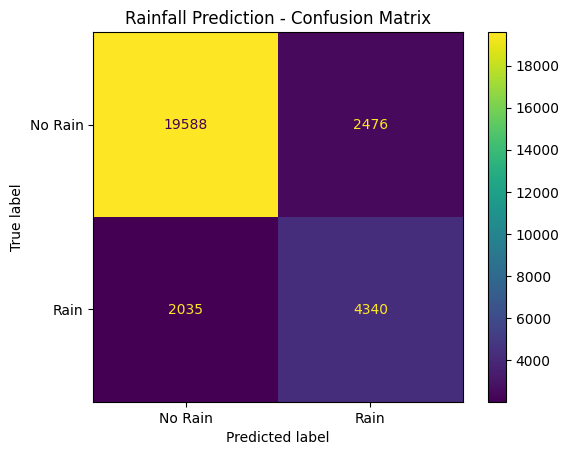

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions on unseen test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

# Display results
print("===== RAINFALL PREDICTION MODEL RESULTS =====")
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No Rain", "Rain"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Rain", "Rain"]
)

display.plot(values_format="d")
plt.title("Rainfall Prediction - Confusion Matrix")
plt.show()

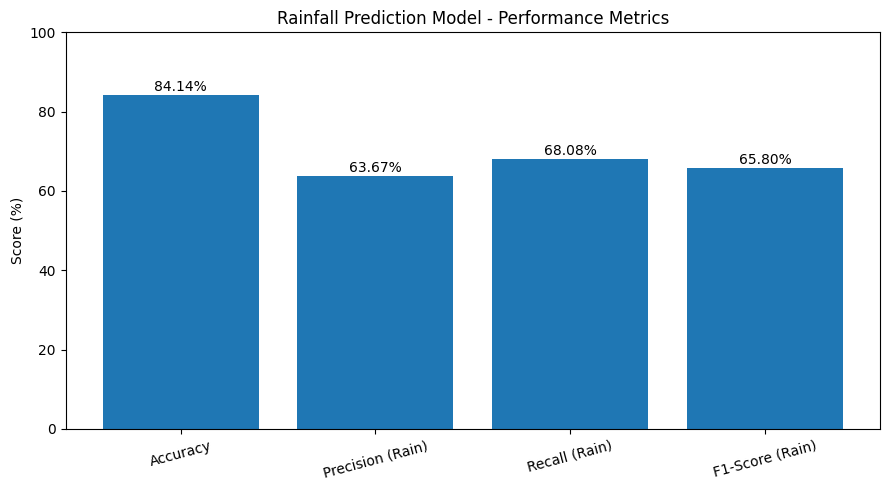

In [12]:
import matplotlib.pyplot as plt

# Evaluation metrics
metrics = {
    "Accuracy": accuracy * 100,
    "Precision (Rain)": precision * 100,
    "Recall (Rain)": recall * 100,
    "F1-Score (Rain)": f1 * 100
}

# Create bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.title("Rainfall Prediction Model - Performance Metrics")
plt.ylabel("Score (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

# Display values above bars
for bar, value in zip(bars, metrics.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

ROC-AUC Score: 0.8833


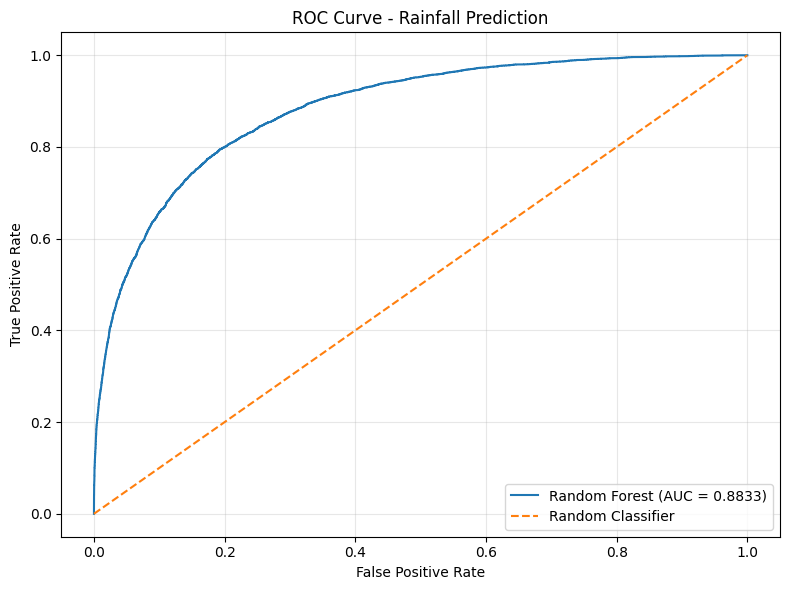

In [13]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Get probability predictions for the Rain class
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve and AUC score
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

# Random guessing baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Rainfall Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

===== TOP 15 MOST IMPORTANT FEATURES =====
           Feature  Importance
  num__Humidity3pm    0.171650
     num__Rainfall    0.071285
     num__Sunshine    0.070557
  num__Pressure3pm    0.057437
num__WindGustSpeed    0.053231
     num__Cloud3pm    0.052859
  num__Pressure9am    0.052315
  num__Humidity9am    0.051014
      num__Temp3pm    0.038606
      num__MinTemp    0.036884
      num__MaxTemp    0.034829
     num__Cloud9am    0.032495
      num__Temp9am    0.029651
 cat__RainToday_No    0.028944
cat__RainToday_Yes    0.024652


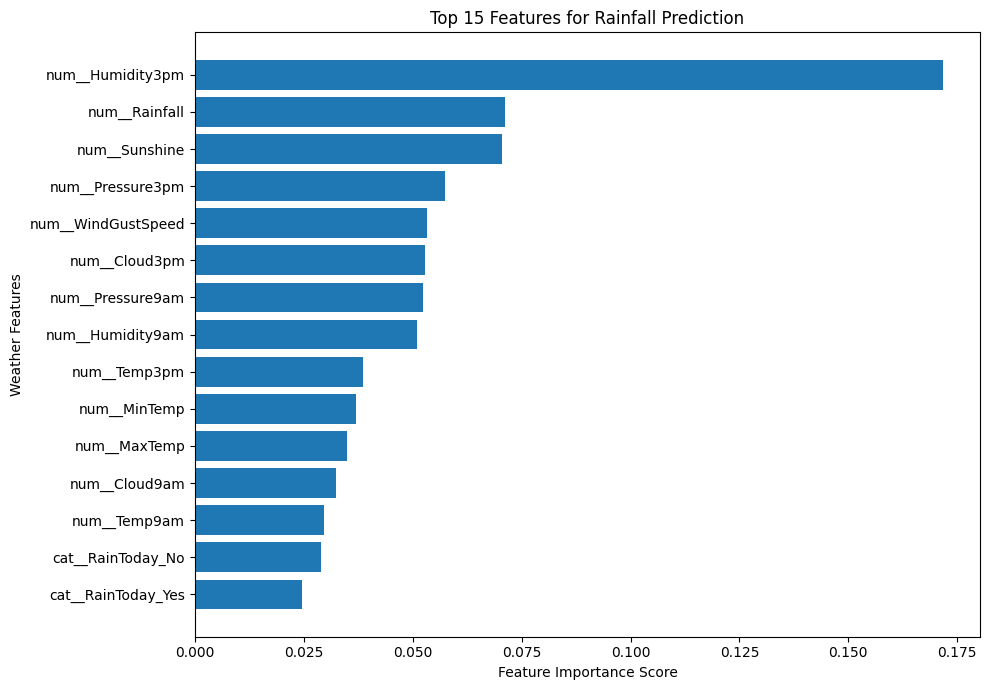

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract the trained Random Forest classifier
rf_model = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Extract feature importance scores
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
print("===== TOP 15 MOST IMPORTANT FEATURES =====")
print(importance_df.head(15).to_string(index=False))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance Score")
plt.ylabel("Weather Features")
plt.title("Top 15 Features for Rainfall Prediction")
plt.tight_layout()
plt.show()

In [15]:
import joblib
import os

# Save the complete pipeline, including preprocessing and model
model_filename = "rainfall_prediction_model.pkl"

joblib.dump(model, model_filename)

print("Model saved successfully!")
print(f"Filename: {model_filename}")
print(f"File size: {os.path.getsize(model_filename) / (1024 * 1024):.2f} MB")

Model saved successfully!
Filename: rainfall_prediction_model.pkl
File size: 74.55 MB


In [16]:
from google.colab import files

files.download("rainfall_prediction_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
import pandas as pd

def predict_rainfall(weather_data):
    """
    Predict whether it will rain tomorrow.

    Input:
        weather_data: Dictionary containing the 21 weather features.

    Output:
        Predicted class and estimated rain probability.
    """

    # Convert input into a DataFrame
    input_df = pd.DataFrame([weather_data])

    # Ensure the input has the same features and order as training
    input_df = input_df[X_train.columns]

    # Make prediction
    prediction = model.predict(input_df)[0]

    # Get estimated probability of rain
    rain_probability = model.predict_proba(input_df)[0][1]

    # Display result
    result = "Rain" if prediction == 1 else "No Rain"

    print("===== RAINFALL PREDICTION =====")
    print(f"Prediction for tomorrow: {result}")
    print(f"Estimated probability of rain: {rain_probability * 100:.2f}%")

    return result, rain_probability

In [19]:
# Select one weather record from the test dataset
sample_weather = X_test.iloc[[0]].copy()

# Make a prediction
prediction = model.predict(sample_weather)[0]
rain_probability = model.predict_proba(sample_weather)[0][1]

print("===== SAMPLE PREDICTION TEST =====")
print(f"Predicted outcome: {'Rain' if prediction == 1 else 'No Rain'}")
print(f"Estimated probability of rain: {rain_probability * 100:.2f}%")

# Show the actual outcome for comparison
actual_outcome = y_test.loc[sample_weather.index[0]]

print(f"Actual outcome: {'Rain' if actual_outcome == 1 else 'No Rain'}")

===== SAMPLE PREDICTION TEST =====
Predicted outcome: No Rain
Estimated probability of rain: 29.02%
Actual outcome: No Rain


In [20]:
!pip -q install gradio

In [21]:
import gradio as gr
import pandas as pd

def predict_from_sample(index):
    # Select a weather record from the test dataset
    sample = X_test.iloc[[int(index)]].copy()

    # Make prediction
    prediction = model.predict(sample)[0]
    probability = model.predict_proba(sample)[0][1]

    # Get actual result for comparison
    actual = y_test.loc[sample.index[0]]

    result = "🌧️ Rain Tomorrow" if prediction == 1 else "☀️ No Rain Tomorrow"
    actual_result = "Rain" if actual == 1 else "No Rain"

    return (
        result,
        f"{probability * 100:.2f}%",
        actual_result
    )

demo = gr.Interface(
    fn=predict_from_sample,
    inputs=gr.Number(
        label="Test Record Index (0 to 28438)",
        value=0,
        precision=0
    ),
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Estimated Rain Probability"),
        gr.Textbox(label="Actual Outcome")
    ],
    title="🌦️ Rainfall Prediction System",
    description="Choose a test record to see the Random Forest model's prediction."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f26d6c396e2af6c419.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [22]:
# Display available locations
locations = sorted(X_train["Location"].dropna().unique().tolist())

print(f"Number of available locations: {len(locations)}")
print("\nFirst 20 locations:")
print(locations[:20])

# Display available wind directions
wind_directions = sorted(
    set(
        X_train["WindGustDir"].dropna().unique()
    )
    | set(
        X_train["WindDir9am"].dropna().unique()
    )
    | set(
        X_train["WindDir3pm"].dropna().unique()
    )
)

print("\nAvailable wind directions:")
print(wind_directions)

# Display valid RainToday values
print("\nRainToday values:")
print(sorted(X_train["RainToday"].dropna().unique().tolist()))

Number of available locations: 49

First 20 locations:
['Adelaide', 'Albany', 'Albury', 'AliceSprings', 'BadgerysCreek', 'Ballarat', 'Bendigo', 'Brisbane', 'Cairns', 'Canberra', 'Cobar', 'CoffsHarbour', 'Dartmoor', 'Darwin', 'GoldCoast', 'Hobart', 'Katherine', 'Launceston', 'Melbourne', 'MelbourneAirport']

Available wind directions:
['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW']

RainToday values:
['No', 'Yes']


In [23]:
import gradio as gr
import pandas as pd

# Get valid categories from the training dataset
locations = sorted(X_train["Location"].dropna().unique().tolist())

wind_directions = sorted(
    set(X_train["WindGustDir"].dropna().unique())
    | set(X_train["WindDir9am"].dropna().unique())
    | set(X_train["WindDir3pm"].dropna().unique())
)

def predict_custom_weather(
    location,
    min_temp,
    max_temp,
    rainfall,
    evaporation,
    sunshine,
    wind_gust_dir,
    wind_gust_speed,
    wind_dir_9am,
    wind_dir_3pm,
    wind_speed_9am,
    wind_speed_3pm,
    humidity_9am,
    humidity_3pm,
    pressure_9am,
    pressure_3pm,
    cloud_9am,
    cloud_3pm,
    temp_9am,
    temp_3pm,
    rain_today
):
    # Construct input using the exact training feature names
    weather_data = {
        "Location": location,
        "MinTemp": min_temp,
        "MaxTemp": max_temp,
        "Rainfall": rainfall,
        "Evaporation": evaporation,
        "Sunshine": sunshine,
        "WindGustDir": wind_gust_dir,
        "WindGustSpeed": wind_gust_speed,
        "WindDir9am": wind_dir_9am,
        "WindDir3pm": wind_dir_3pm,
        "WindSpeed9am": wind_speed_9am,
        "WindSpeed3pm": wind_speed_3pm,
        "Humidity9am": humidity_9am,
        "Humidity3pm": humidity_3pm,
        "Pressure9am": pressure_9am,
        "Pressure3pm": pressure_3pm,
        "Cloud9am": cloud_9am,
        "Cloud3pm": cloud_3pm,
        "Temp9am": temp_9am,
        "Temp3pm": temp_3pm,
        "RainToday": rain_today
    }

    input_df = pd.DataFrame([weather_data])[X_train.columns]

    # Predict
    prediction = model.predict(input_df)[0]
    probability = model.predict_proba(input_df)[0][1]

    result = "🌧️ Rain Tomorrow" if prediction == 1 else "☀️ No Rain Tomorrow"

    return result, f"{probability * 100:.2f}%"


with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("# 🌦️ Rainfall Prediction System")
    gr.Markdown(
        "Enter weather conditions to predict whether it will rain tomorrow."
    )

    with gr.Row():
        location = gr.Dropdown(
            choices=locations,
            value=locations[0],
            label="Location"
        )

        rain_today = gr.Radio(
            choices=["No", "Yes"],
            value="No",
            label="Did it rain today?"
        )

    gr.Markdown("## 🌡️ Temperature and Rainfall")

    with gr.Row():
        min_temp = gr.Number(value=15.0, label="Minimum Temperature (°C)")
        max_temp = gr.Number(value=25.0, label="Maximum Temperature (°C)")
        rainfall = gr.Number(value=0.0, label="Rainfall (mm)")
        evaporation = gr.Number(value=4.0, label="Evaporation (mm)")

    sunshine = gr.Slider(
        minimum=0,
        maximum=14,
        value=7,
        step=0.1,
        label="Sunshine (hours)"
    )

    gr.Markdown("## 💨 Wind Conditions")

    with gr.Row():
        wind_gust_dir = gr.Dropdown(
            choices=wind_directions,
            value="N",
            label="Wind Gust Direction"
        )
        wind_gust_speed = gr.Number(
            value=35,
            label="Wind Gust Speed (km/h)"
        )

    with gr.Row():
        wind_dir_9am = gr.Dropdown(
            choices=wind_directions,
            value="N",
            label="Wind Direction at 9 AM"
        )
        wind_dir_3pm = gr.Dropdown(
            choices=wind_directions,
            value="N",
            label="Wind Direction at 3 PM"
        )

    with gr.Row():
        wind_speed_9am = gr.Number(value=15, label="Wind Speed at 9 AM (km/h)")
        wind_speed_3pm = gr.Number(value=20, label="Wind Speed at 3 PM (km/h)")

    gr.Markdown("## 💧 Humidity and Atmospheric Pressure")

    with gr.Row():
        humidity_9am = gr.Slider(
            0, 100, value=60, label="Humidity at 9 AM (%)"
        )
        humidity_3pm = gr.Slider(
            0, 100, value=45, label="Humidity at 3 PM (%)"
        )

    with gr.Row():
        pressure_9am = gr.Number(
            value=1015, label="Pressure at 9 AM (hPa)"
        )
        pressure_3pm = gr.Number(
            value=1012, label="Pressure at 3 PM (hPa)"
        )

    gr.Markdown("## ☁️ Cloud Cover and Temperature")

    with gr.Row():
        cloud_9am = gr.Slider(
            0, 8, value=4, step=1, label="Cloud Cover at 9 AM (oktas)"
        )
        cloud_3pm = gr.Slider(
            0, 8, value=5, step=1, label="Cloud Cover at 3 PM (oktas)"
        )

    with gr.Row():
        temp_9am = gr.Number(value=20, label="Temperature at 9 AM (°C)")
        temp_3pm = gr.Number(value=24, label="Temperature at 3 PM (°C)")

    predict_button = gr.Button("🌧️ Predict Tomorrow's Rainfall", variant="primary")

    prediction_output = gr.Textbox(label="Prediction")
    probability_output = gr.Textbox(label="Estimated Rain Probability")

    predict_button.click(
        fn=predict_custom_weather,
        inputs=[
            location,
            min_temp,
            max_temp,
            rainfall,
            evaporation,
            sunshine,
            wind_gust_dir,
            wind_gust_speed,
            wind_dir_9am,
            wind_dir_3pm,
            wind_speed_9am,
            wind_speed_3pm,
            humidity_9am,
            humidity_3pm,
            pressure_9am,
            pressure_3pm,
            cloud_9am,
            cloud_3pm,
            temp_9am,
            temp_3pm,
            rain_today
        ],
        outputs=[prediction_output, probability_output]
    )

demo.launch(share=True)

/tmp/ipykernel_797/2790407213.py:72: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6faa190394a1d9afd6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
